=== HASIL EVALUASI MODEL KNN (k=5) ===
Akurasi Model : 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



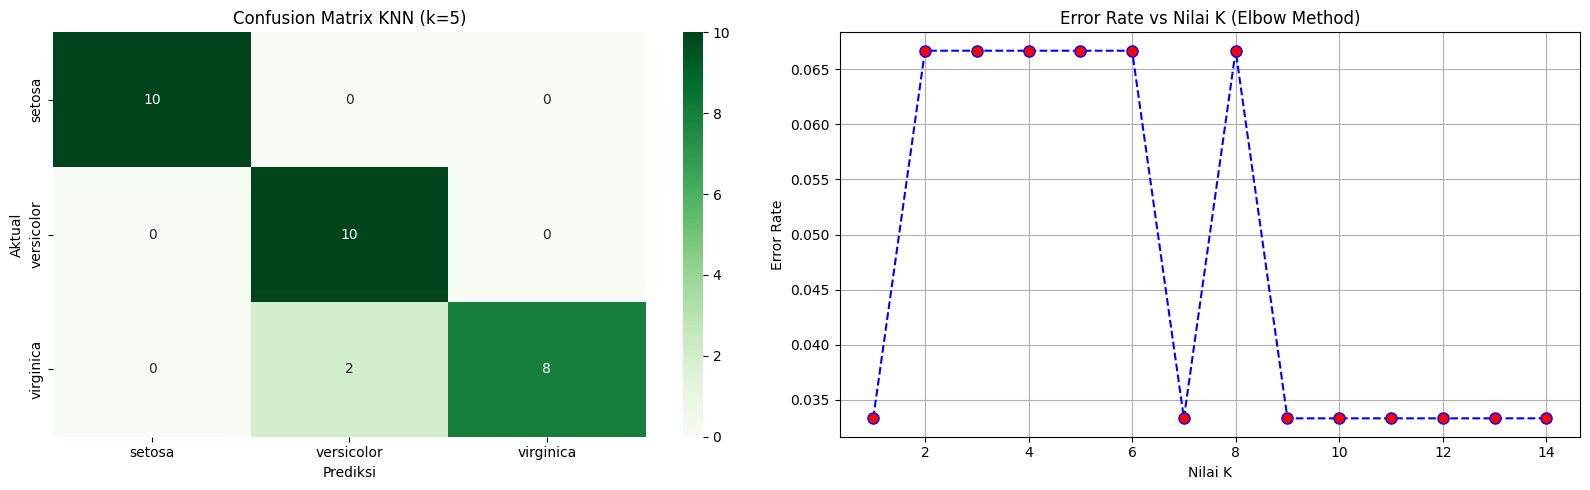

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. LOAD DATASET
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

# 2. PEMBERSIHAN DATA & PREPROCESSING
# A. Cek missing values
df = df.dropna()

# B. Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['species'])
y = df['species']

# C. Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# D. Scaling Fitur (SANGAT WAJIB untuk KNN karena berbasis jarak!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. MENCARI NILAI K TERBAIK (Elbow Method)
error_rate = []

for k in range(1, 15):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred_k = knn.predict(X_test_scaled)
    error_rate.append(np.mean(pred_k != y_test))

# Pilih k terbaik (misal k=5)
best_k = 5
model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train_scaled, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print(f"=== HASIL EVALUASI MODEL KNN (k={best_k}) ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Visualisasi 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[0],
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
axes[0].set_title(f"Confusion Matrix KNN (k={best_k})")

# Visualisasi 2: Grafik Error Rate vs Nilai K (Mencari K Optimal)
axes[1].plot(range(1, 15), error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=8)
axes[1].set_title("Error Rate vs Nilai K (Elbow Method)")
axes[1].set_xlabel("Nilai K")
axes[1].set_ylabel("Error Rate")
axes[1].grid(True)

plt.tight_layout()
plt.show()